# Pipeline Project

You will be using the provided data to create a machine learning model pipeline.

You must handle the data appropriately in your pipeline to predict whether an
item is recommended by a customer based on their review.
Note the data includes numerical, categorical, and text data.

You should ensure you properly train and evaluate your model.

## The Data

The dataset has been anonymized and cleaned of missing values.

There are 8 features for to use to predict whether a customer recommends or does
not recommend a product.
The `Recommended IND` column gives whether a customer recommends the product
where `1` is recommended and a `0` is not recommended.
This is your model's target/

The features can be summarized as the following:

- **Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.
- **Age**: Positive Integer variable of the reviewers age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product high level division.
- **Department Name**: Categorical name of the product department name.
- **Class Name**: Categorical name of the product class name.

The target:
- **Recommended IND**: Binary variable stating where the customer recommends the product where 1 is recommended, 0 is not recommended.

# StyleSense Forecasting

**Goal:** Whether the customer recommends a product (Recommends : 1, Not_Recommends : 0)

**Approach:** Scikit learn Pipeline that contains:  imputation | scaling | one-hot encoding | spacy test processing | TF IDF | Classifer; Nothing is preprocessed outside the piplein

Steps
1. Split data ( 90 % train ; 10 % held-out test )
2. Build the pipeline : numeric, categorical and text branches in a `ColumnTransformer` 
3. Baseline 
4. Tune using GridSearchCV 

In [2]:
import numpy as np
import pandas as pd
import shutil
import tempfile
from pathlib import Path
import joblib  # trained pipeline saved usnig joblib library
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(ConfusionMatrixDisplay,classification_report,
    make_scorer,precision_score,
    recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV,StratifiedKFold,
    cross_validate, train_test_split)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import (FunctionTransformer,
    OneHotEncoder, StandardScaler)

# Custom transformers in custom_transformers.py
from custom_transformers import (CountCharacter, JoinTextColumns,
    SpacyLemmatizer,SpacyPosRatios,log1p_clipped)

RANDOM_STATE = 27 #Can be any number
DATA_PATH = Path("data/reviews.csv")
MODEL_PATH = Path("models/recommender_trained_pp.joblib")
TARGET = "Recommended IND"

#Change default appearance of plots
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False,
                     "axes.spines.right": False})

In [3]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 77.4 MB/s eta 0:00:0000:010:01

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


## Load Data

In [4]:
import pandas as pd

# Load data
data = pd.read_csv(
    'data/reviews.csv',
)

data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              18442 non-null  int64 
 1   Age                      18442 non-null  int64 
 2   Title                    18442 non-null  object
 3   Review Text              18442 non-null  object
 4   Positive Feedback Count  18442 non-null  int64 
 5   Division Name            18442 non-null  object
 6   Department Name          18442 non-null  object
 7   Class Name               18442 non-null  object
 8   Recommended IND          18442 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.3+ MB


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


## Preparing features (`X`) & target (`y`)

In [5]:
df = data

# separate features from labels
# X = data.drop('Recommended IND', axis=1)
# y = data['Recommended IND'].copy()
# Separate the features from the label
X = df.drop(columns=TARGET)
y = df[TARGET].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [6]:
# # Split data into train and test sets
# from sklearn.model_selection import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y,
#     test_size=0.1,
#     shuffle=True,
#     random_state=27,
# )
# stratify=y keeps the 82/18 class ratio identical in train and test
X_train, X_test, y_train, y_test = train_test_split(X,y,
    test_size=0.1,shuffle=True,stratify=y,random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows") 
# Train: 16,597 rows | Test: 1,845 rows

print("Share recommended  train:", round(y_train.mean(), 4),
      "| test:", round(y_test.mean(), 4))
# Share recommended  train: 0.8162 | test: 0.8163

Train: 16,597 rows | Test: 1,845 rows
Share recommended  train: 0.8162 | test: 0.8163


# Data Exploration
Note that clothing ID is id for cloth (categorical), say id for pants, id for skirts.

**Data Types**

Numerical: Age, Positive_Feedback_Count.

Categorical: Clothing ID, Division Name, Department Name, Class Name.

Text: Title, Review_Text.

In [7]:
NUM_FEATURES = ["Age", "Positive Feedback Count"]
CAT_FEATURES = ["Clothing ID", "Division Name", 
                "Department Name","Class Name"]
TEXT_FEATURES = ["Title", "Review Text"]

# CHECK: Every feature must belong to exactly one group
assert sorted(NUM_FEATURES + CAT_FEATURES + TEXT_FEATURES) == sorted(X.columns)

print("Missing values in dataset")
print(data.isna().sum()) #NONE


X_train[NUM_FEATURES].describe().round(2)

Missing values in dataset
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
Recommended IND            0
dtype: int64


,Age,Positive Feedback Count
count,16597.00,16597.00
mean,43.43,2.70
std,12.25,5.94
min,18.00,0.00
25%,34.00,0.00
50%,42.00,1.00
75%,52.00,3.00
max,99.00,122.00


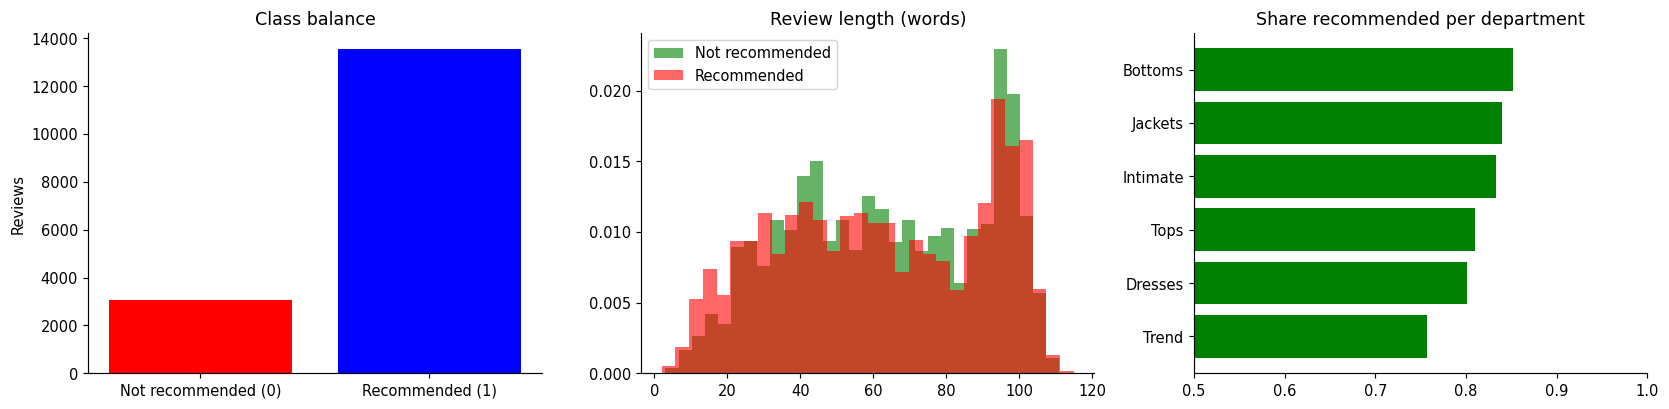

In [8]:
## Exploratory Data Analysis
# Class balance | review length | recommend_rate by department
def plot_data_overview(features, target):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    counts = target.value_counts().sort_index()
    axes[0].bar(["Not recommended (0)", "Recommended (1)"], counts.values,
                color=[ "red","blue"])
    axes[0].set_title("Class balance")
    axes[0].set_ylabel("Reviews")
    n_words = features["Review Text"].str.split().str.len()
    for label, color, name in [(0, "green", "Not recommended"),
                               (1, "red", "Recommended")]:
        axes[1].hist(n_words[target == label], bins=30, density=True,
                     alpha=0.6, color=color, label=name)
    axes[1].set_title("Review length (words)")
    axes[1].legend()
    rate = target.groupby(features["Department Name"]).mean().sort_values()
    axes[2].barh(rate.index, rate.values, color="green")
    axes[2].set_title("Share recommended per department")
    axes[2].set_xlim(0.5, 1.0)
    plt.tight_layout()
    plt.show()


plot_data_overview(X_train, y_train)

In [9]:
# What do reviews look like in each class?
sample = X_train.assign(recommended=y_train).groupby("recommended").sample(
    2, random_state=RANDOM_STATE)


for _, row in sample.iterrows():
    print(row["recommended"], row["Title"], row["Review Text"][:175], "\n")



0 Raglan sleeve style did not work with larger bust I saw the photo of the young woman wearing this dress in the reviews and she looked beautiful, i on the other hand looked awful. the fabric of the entire dress is quite stiff, 

0 Complete mess I love eva franco 
this is a very poor version ! bias seams are puckery... zipper is bubbled 
felt great looked like fun but too much if a mess to be fixed. 

1 Adorable These pants are soft, fun print and comfy. they are a drop crotch, but the cut is flattering without bunching up between legs. they are perfect for pjs all day type day! 

1 Very nice material, soft! I got this in the brown and absolutely love it. this is perfect for cool weather. i'm super particular about fabric quality and this cardigan does not disappoint 



## Building Pipeline

In [10]:
# All data types get their own branch and all branches are merged by a ColumnTransformer.

# 041 NUMERICAL FEATURES
# Impute (median); Log(1+x) as range of value from 0 to 59 (log 0 is undefined)
# Standard scaler transforms data with mean 0 and sd 1

def build_numeric_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(log1p_clipped,
                                    feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),])

In [11]:
# 042 CATAGORICAL FEATURES
# Impute (most frequent category)
# One Hot Encoder: handle_unknown="infrequent_if_exist" tells the encoder: 
# Groups categories that appear too infrequently into one category.
# Model Robust to previously unseen categories.

def build_categorical_pipeline(min_frequency=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=min_frequency)),])

In [12]:
# 043 TEXT FEATURES
# Lots of transofformations including
# Character counts : Review length and punctuation usage
# POS ratios : Grammatical structure of reviews
# Term Frequency-Inverse Document Frequency (TF-IDF)
# TF-IDF measures how important a word is in a particular review compared with how frequently it appears across all reviews
# sublinear_tf=True, Scikit-learn applies logarithmic scaling to term frequency

def build_text_pipeline(ngram_range=(1, 1), min_df=1, max_features=None):
    character_counts = Pipeline([
        ("counts", FeatureUnion([
            ("spaces", CountCharacter(character=" ")),
            ("exclamations", CountCharacter(character="!")),
            ("question_marks", CountCharacter(character="?")),])),
        ("log", FunctionTransformer(log1p_clipped,
                                    feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),])
    pos_shares = Pipeline([
        ("ratios", SpacyPosRatios()),
        ("scaler", StandardScaler()),])
    tfidf = Pipeline([
        ("lemmatizer", SpacyLemmatizer()),
        ("tfidf", TfidfVectorizer(ngram_range=ngram_range, min_df=min_df,
                                  max_features=max_features,
                                  sublinear_tf=True)),])
    return Pipeline([
        ("join", JoinTextColumns(separator=". ")),
        ("features", FeatureUnion([
            ("char_counts", character_counts),
            ("pos", pos_shares),
            ("tfidf", tfidf),])),
            ])

In [13]:
# 044 FULL MODEL PIPELINE
# ColumnTransformer : different types of data require different preprocessing techniques.
def build_model_pipeline(memory=None):
    preprocessor = ColumnTransformer([
        ("num", build_numeric_pipeline(), NUM_FEATURES),
        ("cat", build_categorical_pipeline(), CAT_FEATURES),
        ("text", build_text_pipeline(), TEXT_FEATURES),
    ])
    classifier = LogisticRegression(solver="liblinear", max_iter=1000,
                                    random_state=RANDOM_STATE)
    return Pipeline([("preprocessor", preprocessor),
                     ("classifier", classifier)], memory=memory)


build_model_pipeline()

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function log1p_clipped at 0x7e173298d360>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Positive Feedback Count']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(st...
                                                                                                                                        func=<function log1p_clipped at 0x7e173298d360>)),
                                                                                                                   ('scaler',
                                                                                                                    StandardScaler())])),
                                                                                                  ('pos',
                                                                                                   Pipeline(steps=[('ratios',
                                                                                                                    SpacyPosRatios()),
                                                                                                                   ('scaler',
                                                                                                                    StandardScaler())])),
                                                                                                  ('tfidf',
                                                                                                   Pipeline(steps=[('lemmatizer',
                                                                                                                    SpacyLemmatizer()),
                                                                                                                   ('tfidf',
                                                                                                                    TfidfVectorizer(sublinear_tf=True))]))]))]),
                                                  ['Title', 'Review Text'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=27,
                                    solver='liblinear'))])

## Baseline

In [14]:
#05 BASELINE : Pipeline with default settings
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
    "precision_class0": make_scorer(precision_score, pos_label=0),
    "recall_class0": make_scorer(recall_score, pos_label=0),
}
REFIT_METRIC = "f1_macro"

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_scores = cross_validate(build_model_pipeline(), X_train, y_train,
                                 cv=cv, scoring=SCORING, n_jobs=-1)
baseline_cv = pd.Series(
    {name: baseline_scores[f"test_{name}"].mean() for name in SCORING},
    name="baseline (default settings)",
)
baseline_cv.round(4) 

accuracy            0.8946
precision           0.9102
recall              0.9662
f1                  0.9374
f1_macro            0.8026
roc_auc             0.9410
precision_class0    0.7934
recall_class0       0.5767
Name: baseline (default settings), dtype: float64

## Finetune

In [15]:
# 06 FINE TUNE WITH GridSearchCV
TFIDF = "preprocessor__text__features__tfidf__tfidf"
ONEHOT = "preprocessor__cat__onehot"
CLASSIFIER = "classifier"

# Combinations = 288 (np.prod([2,3,3,2,4, 2]),5 CV Folds = 1440.
param_grid = {
    f"{TFIDF}__ngram_range": [(1, 1), (1, 2)],
    f"{TFIDF}__min_df": [1, 2, 5],
    f"{TFIDF}__max_features": [3000, 10000, None],
    f"{ONEHOT}__min_frequency": [10, 50],
    f"{CLASSIFIER}__C": [0.5, 2, 8, 32],
    f"{CLASSIFIER}__class_weight": [None, "balanced"],
}
n_candidates = int(np.prod([len(values) for values in param_grid.values()]))
print(f"{n_candidates} candidates x {cv.get_n_splits()} folds "
      f"= {n_candidates * cv.get_n_splits()} fits")


# Temporary on-disk cache 
cache_dir = Path(tempfile.mkdtemp(prefix="stylesense_cache_"))

grid_search = GridSearchCV(
    estimator=build_model_pipeline(memory=joblib.Memory(cache_dir, verbose=0)),
    param_grid=param_grid,
    scoring=SCORING,
    refit=REFIT_METRIC,   # refit best candidate training data
    cv=cv,
    n_jobs=-1,            # processors
    verbose=1,
)
grid_search.fit(X_train, y_train)  #Takes time (dependent on pc config)

# Clean up the cache & detach it from final pipeline
shutil.rmtree(cache_dir, ignore_errors=True)
best_model = grid_search.best_estimator_
best_model.set_params(memory=None)

print("Best CV macro F1:", round(grid_search.best_score_, 4))
print("Best parameters:")
for name, value in grid_search.best_params_.items():
    print(f"  {name.split('__')[-1]:>14}: {value}")


288 candidates x 5 folds = 1440 fits
Fitting 5 folds for each of 288 candidates, totalling 1440 fits
Best CV macro F1: 0.8497
Best parameters:
               C: 8
    class_weight: balanced
   min_frequency: 50
    max_features: None
          min_df: 2
     ngram_range: (1, 2)


In [16]:
# 061. Results
def summarize_cv_results(search, n_top=10):
    """Top candidates : readable table : parameters + CV metrics"""
    results = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in results if c.startswith("param_")]
    metric_cols = ["mean_test_f1_macro", "mean_test_accuracy",
                   "mean_test_precision_class0", "mean_test_recall_class0",
                   "mean_test_roc_auc"]
    table = results.sort_values("rank_test_f1_macro").head(n_top)
    table = table[param_cols + metric_cols].copy()
    table.columns = [c.split("__")[-1].replace("mean_test_", "cv_")
                     .replace("param_", "") for c in table.columns]
    return table.reset_index(drop=True).round(4)


summarize_cv_results(grid_search)

,C,class_weight,min_frequency,max_features,min_df,ngram_range,cv_f1_macro,cv_accuracy,cv_precision_class0,cv_recall_class0,cv_roc_auc
0,8.0,balanced,50,None,2,"(1, 2)",0.8497,0.9061,0.7207,0.7993,0.9502
1,32.0,balanced,50,None,1,"(1, 2)",0.8493,0.9088,0.7466,0.7633,0.9510
2,8.0,balanced,10,None,2,"(1, 2)",0.8491,0.9056,0.7194,0.7987,0.9485
3,8.0,balanced,10,None,1,"(1, 2)",0.8486,0.9058,0.7226,0.7925,0.9494
4,8.0,balanced,50,None,1,"(1, 2)",0.8485,0.9055,0.7209,0.7941,0.9511
5,32.0,balanced,10,None,1,"(1, 2)",0.8471,0.9075,0.7429,0.7600,0.9493
6,32.0,balanced,50,None,2,"(1, 2)",0.8452,0.9057,0.7343,0.7636,0.9483
7,8.0,balanced,50,None,5,"(1, 2)",0.8444,0.9015,0.7031,0.8046,0.9477
8,2.0,balanced,10,None,5,"(1, 2)",0.8435,0.8974,0.6771,0.8452,0.9483
9,2.0,balanced,10,10000,2,"(1, 2)",0.8434,0.8970,0.6746,0.8495,0.9483


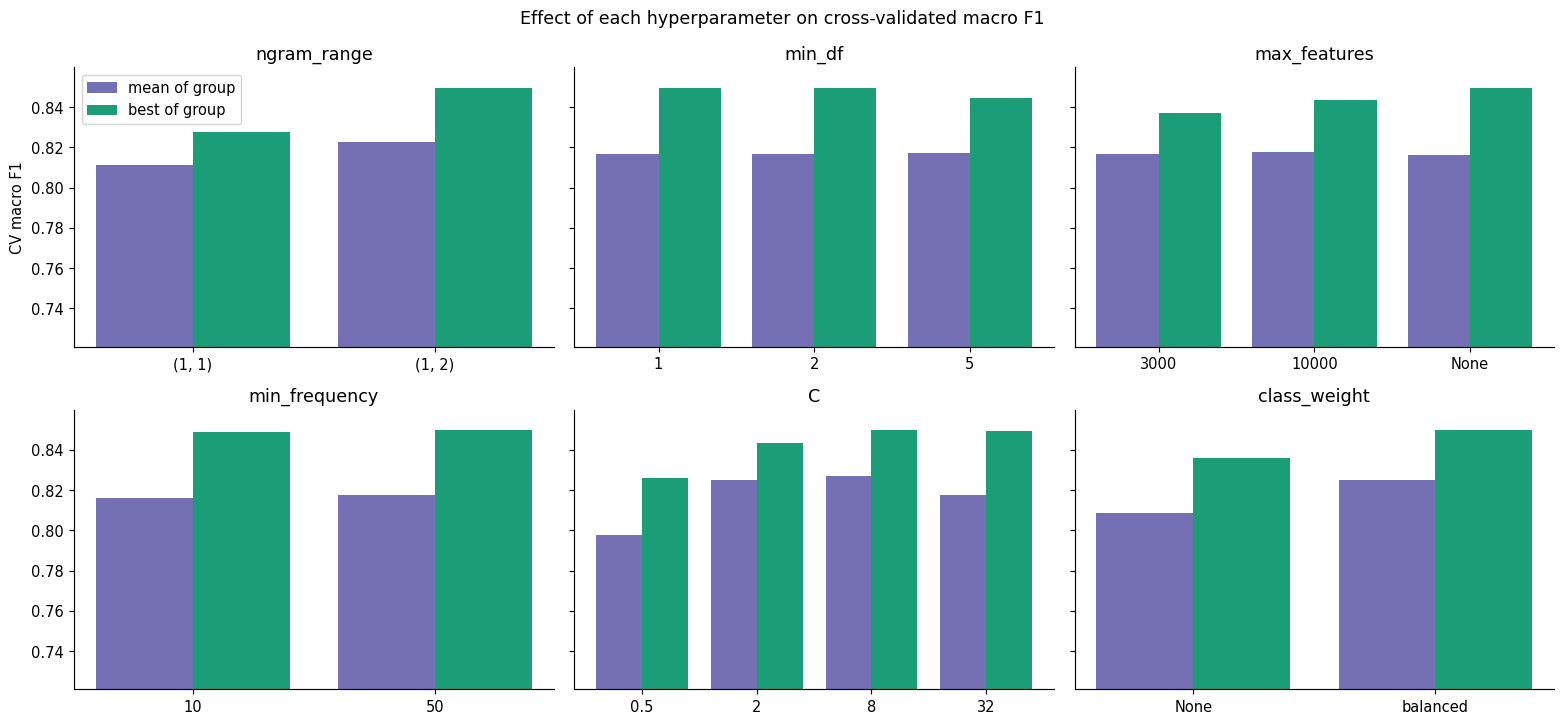

,baseline (default settings),tuned (best grid candidate)
accuracy,0.8946,0.9061
precision,0.9102,0.9537
recall,0.9662,0.9301
f1,0.9374,0.9417
f1_macro,0.8026,0.8497
roc_auc,0.9410,0.9502
precision_class0,0.7934,0.7207
recall_class0,0.5767,0.7993


In [17]:
def plot_hyperparameter_effects(search, grid, metric="mean_test_f1_macro"):
    """Mean en best CV score for every value of each hyperparameter"""
    results = pd.DataFrame(search.cv_results_)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
    for ax, (param, values) in zip(axes.ravel(), grid.items()):
        labels = [str(value) for value in values]
        keys = [str(p[param]) for p in search.cv_results_["params"]]
        grouped = results[metric].groupby(keys)
        mean = grouped.mean().reindex(labels)
        best = grouped.max().reindex(labels)
        positions = np.arange(len(labels))
        ax.bar(positions - 0.2, mean.values, width=0.4, label="mean of group",
               color="#7570b3")
        ax.bar(positions + 0.2, best.values, width=0.4, label="best of group",
               color="#1b9e77")
        ax.set_xticks(positions)
        ax.set_xticklabels(labels)
        ax.set_title(param.split("__")[-1])
        ax.set_ylim(results[metric].min() - 0.01, results[metric].max() + 0.01)
    axes[0, 0].set_ylabel("CV macro F1")
    axes[0, 0].legend()
    plt.suptitle("Effect of each hyperparameter on Cross Validated macro F1")
    plt.tight_layout()
    plt.show()


plot_hyperparameter_effects(grid_search, param_grid)

# Tuned vs. baseline, both measured by 5-fold CV on training data
tuned_cv = pd.Series(
    {name: grid_search.cv_results_[f"mean_test_{name}"][
        grid_search.best_index_]
     for name in SCORING},
    name="tuned (best grid candidate)",
)
pd.concat([baseline_cv, tuned_cv], axis=1).round(4)


## Evaluation Held out Test set

In [18]:
# 07 Final Evaluation Held out Test set
def evaluate_model(model, features, target):
    """Print a report and return key metrics for a fitted pipeline."""
    predictions = model.predict(features)
    probabilities = model.predict_proba(features)[:, 1]
    print(classification_report(
        target, predictions,
        target_names=["not recommended (0)", "recommended (1)"], digits=3))
    return pd.Series({
        "accuracy": (predictions == target).mean(),
        "precision (class 1)": precision_score(target, predictions),
        "recall (class 1)": recall_score(target, predictions),
        "precision (class 0)": precision_score(target, predictions,
                                               pos_label=0),
        "recall (class 0)": recall_score(target, predictions, pos_label=0),
        "roc_auc": roc_auc_score(target, probabilities),
    }, name="test set")


test_metrics = evaluate_model(best_model, X_test, y_test)
test_metrics.round(4)

                     precision    recall  f1-score   support

not recommended (0)      0.689     0.796     0.739       339
    recommended (1)      0.953     0.919     0.935      1506

           accuracy                          0.896      1845
          macro avg      0.821     0.858     0.837      1845
       weighted avg      0.904     0.896     0.899      1845



accuracy               0.8965
precision (class 1)    0.9525
recall (class 1)       0.9190
precision (class 0)    0.6888
recall (class 0)       0.7965
roc_auc                0.9516
Name: test set, dtype: float64

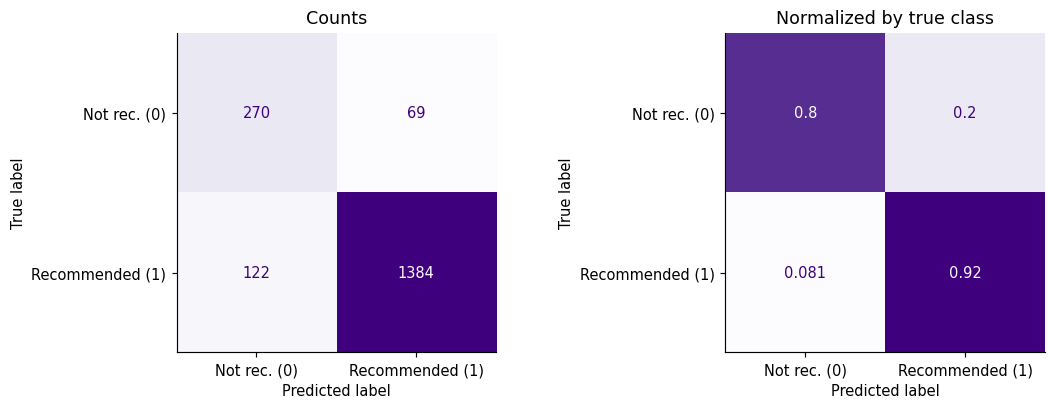

Reference: always predicting 'recommended' gives accuracy 0.816


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, normalize, title in zip(axes, [None, "true"],
                                ["Counts", "Normalized by true class"]):
    ConfusionMatrixDisplay.from_estimator(
        best_model, X_test, y_test, normalize=normalize, ax=ax,
        display_labels=["Not rec. (0)", "Recommended (1)"],
        cmap="Purples", colorbar=False)
    ax.set_title(title)


plt.tight_layout()
plt.show()

majority = max(y_test.mean(), 1 - y_test.mean())
print(f"Reference: always predicting 'recommended' gives accuracy "
      f"{majority:.3f}")


**Interpretation of Evaluation Held out Test set** : The tuned pipeline reaches about 

0.90 accuracy and 0.84 macro F1 on unseen reviews,relatively close to its cross-validated macro F1 of 0.85, suggesting reasonable generalization. 

Accuracy alone is only ~8% above the reference (0.816); the useful part is the minority class: 

~79.6% of non-recommended reviews are found (recall), and 

~68.8% of reviews flagged as non-recommended truly are (precision). 

The test set holds 339 such reviews, so these two figures carry some uncertainty.

## Drivers of this prediction

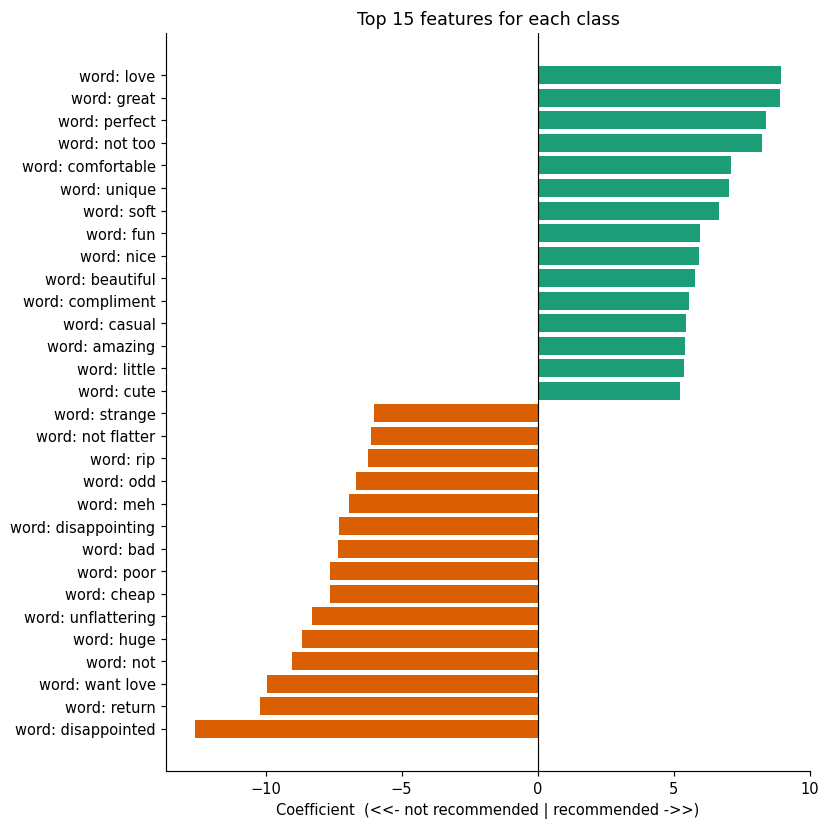

Strongest non-word features:


Clothing ID_964     1.139255
Clothing ID_883    -1.132416
Clothing ID_941    -1.087029
Clothing ID_834     1.003346
Clothing ID_1008    0.940239
Clothing ID_1028   -0.859231
Clothing ID_830     0.796119
Clothing ID_1087   -0.751495
dtype: float64

In [22]:
# 08 What drives the prediction?
def clean_feature_name(name):
    """ColumnTransformer feature names shortened for plot"""
    if name.startswith("text__tfidf__"):
        return "word: " + name.split("__")[-1]
    return name.split("__")[-1]


def plot_top_coefficients(model, n_top=15):
    names = model.named_steps["preprocessor"].get_feature_names_out()
    names = np.array([clean_feature_name(name) for name in names])
    coefficients = model.named_steps["classifier"].coef_[0]
    order = np.argsort(coefficients)
    picked = np.concatenate([order[:n_top], order[-n_top:]])
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.barh(names[picked], coefficients[picked],
            color=np.where(coefficients[picked] > 0, "#1b9e77", "#d95f02"))
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top {n_top} features for each class")
    ax.set_xlabel("Coefficient  (<<- not recommended | recommended ->>)")
    plt.tight_layout()
    plt.show()
    return pd.Series(coefficients, index=names)


coefficients = plot_top_coefficients(best_model)
non_word = coefficients[~coefficients.index.str.startswith("word: ")]
print("Strongest non-word features:")
non_word.reindex(non_word.abs().sort_values(ascending=False).index).head(8)

**Interpretation**

The strongest drivers are words and word pairs.

Positive sentiment ("love", "great", "perfect", "comfortable") pushes towards recommended.

"disappointed", "return", "not flattering", "cheap" and "huge" push towards not recommended.

Pairs such as "not flattering" show why negations were retained and why including bigrams or word pairs helped.

Among the non-word features, individual product IDs have large coefficients, and this suggests that some products are more strongly associated with positive or negative recommendations than others, even after accounting for review text.

In [30]:
# 09 Pipeline on new  data to show this framework can handle nul value
new_reviews = pd.DataFrame([
    {"Clothing ID": 1078, "Age": 34, "Title": "Love it!",
     "Review Text": "Gorgeous dress, fits perfectly well and fabric feels "
                    "great. I get compliments every time when I wear it!",
     "Positive Feedback Count": 3, "Division Name": "General",
     "Department Name": "Dresses", "Class Name": "Dresses"},
    {"Clothing ID": 862, "Age": 52, "Title": "Disappointed",
     "Review Text": "The material is cheap and itchy. It runs too small and "
                    "I would not recommend it. Returning it ASAP.",
     "Positive Feedback Count": 0, "Division Name": "General",
     "Department Name": "Tops", "Class Name": "Knits"},
    {"Clothing ID": 1095, "Age": 41, "Title": "Five stars",
     "Review Text": None,
     "Positive Feedback Count": 1, "Division Name": "General Petite",
     "Department Name": "Bottoms", "Class Name": "Pants"},
])

predictions = pd.DataFrame({
    "review": new_reviews["Review Text"].fillna("(no text)").str[:55] + "...",
    "predicted": best_model.predict(new_reviews),
    "p(recommend)": best_model.predict_proba(new_reviews)[:, 1].round(3),
})
predictions

,review,predicted,p(recommend)
0,"Gorgeous dress, fits perfectly well and fabric...",1,0.998
1,The material is cheap and itchy. It runs too s...,0,0.000
2,(no text)...,1,0.519


## Save Model using Joblib

In [31]:
# Saves the Fitted Pipeline - can be reloaded with joblib.load
# customer_transformers.py must be imported when running the script
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(best_model, MODEL_PATH)

# check reproducibility
reloaded = joblib.load(MODEL_PATH)
assert (reloaded.predict(X_test) == best_model.predict(X_test)).all()
print(f"Saved to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB); "
      "reloaded model reproduces the test predictions.")

Saved to models/recommender_trained_pp.joblib (1.9 MB); reloaded model reproduces the test predictions.
